## Dependencies

This notebook uses the `generative_eeg_augmentation` library. Ensure the package is installed:

```bash
pip install -e .
```

The library provides:
- **Models**: Pre-trained GAN generators and discriminators
- **Data Loading**: Automated EEG dataset loading with preprocessing
- **Metrics**: Time-domain and frequency-domain evaluation metrics
- **Visualizations**: Statistical comparison, waveform, PSD, and heatmap plotting functions

# Spectral and Temporal Domain Consistency Analysis

This module thoroughly evaluates the realism and quality of synthetic EEG signals generated by your GAN in both temporal and frequency domains.

In [1]:
# Imports
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import kurtosis, skew
from scipy.signal import welch
import torch
import torch.nn as nn
import mne

# Force reload library modules to pick up latest changes
import importlib
import generative_eeg_augmentation.models.gan
import generative_eeg_augmentation.data.loader
import generative_eeg_augmentation.eval.eeg_metrics
import generative_eeg_augmentation.plots.eeg_visualizations

importlib.reload(generative_eeg_augmentation.models.gan)
importlib.reload(generative_eeg_augmentation.data.loader)
importlib.reload(generative_eeg_augmentation.eval.eeg_metrics)
importlib.reload(generative_eeg_augmentation.plots.eeg_visualizations)

# Library imports - refactored from inline definitions
from generative_eeg_augmentation.models.gan import load_generator
from generative_eeg_augmentation.data.loader import load_all_preprocessed
from generative_eeg_augmentation.eval.eeg_metrics import (
    compute_time_domain_features,
    compute_psd,
    compute_all_band_powers,
    EEG_BANDS
)
from generative_eeg_augmentation.plots.eeg_visualizations import (
    plot_statistical_comparison,
    plot_waveforms,
    plot_psd_comparison,
    plot_band_power_comparison,
    plot_similarity_heatmap
)

# Seed for reproducibility
torch.manual_seed(42)
np.random.seed(42)

sns.set_theme(style="whitegrid", palette="deep", font_scale=1.1)

# Device configuration
device = "mps" if torch.mps.is_available() else "cpu"
print(f"Using device: {device}")

Using device: mps


### Loading EEG data

This is to provide baseline distribution to asses GAN authenticity.

In [2]:
# Path configurations
models_path = "./../exploratory notebooks/models"
preprocessed_path = "./../data/preprocessed/"

In [3]:
# Load preprocessed EEG data using library function
# This replaces the inline load_data function with the library version
real_data, real_labels = load_all_preprocessed()

Loaded preprocessed EEG data shape: (250, 63, 1001)
Loaded labels shape: (250, 2)


In [4]:
# Convert to torch tensors and move to device
real_data = torch.from_numpy(real_data).float().to(device)
real_labels = torch.from_numpy(real_labels).float().to(device)

print("Real EEG data loaded. Shape:", real_data.shape)
print("Real labels shape:", real_labels.shape)

Real EEG data loaded. Shape: torch.Size([250, 63, 1001])
Real labels shape: torch.Size([250, 2])


In [5]:
# Load pre-trained generator using library function
# This replaces the inline EEGGenerator class definition
latent_dim = 100
n_channels = 63
target_signal_len = real_data.shape[2]
num_classes = 2

generator = load_generator(
    model_variant="original",
    device=device,
    latent_dim=latent_dim,
    n_channels=n_channels,
    target_signal_len=target_signal_len,
    num_classes=num_classes
)

print("Best GAN model loaded successfully.")

Best GAN model loaded successfully.


In [6]:
# synthetic data

# Synthetic EEG embeddings
noise = torch.randn(real_data.size(0), latent_dim).to(device)
synthetic_data = generator(noise, real_labels)

In [7]:
# verification of loading
print(f"Real EEG shape: {real_data.shape}")
print(f"Synthetic EEG shape: {synthetic_data.shape}")

Real EEG shape: torch.Size([250, 63, 1001])
Synthetic EEG shape: torch.Size([250, 63, 1001])


##  Time-Domain Analysis

In [8]:
# Compute time-domain features using library function
# (replaces inline compute_time_domain_features)
real_mean, real_var, real_kurt, real_skew = compute_time_domain_features(real_data)
synthetic_mean, synthetic_var, synthetic_kurt, synthetic_skew = compute_time_domain_features(synthetic_data.detach())

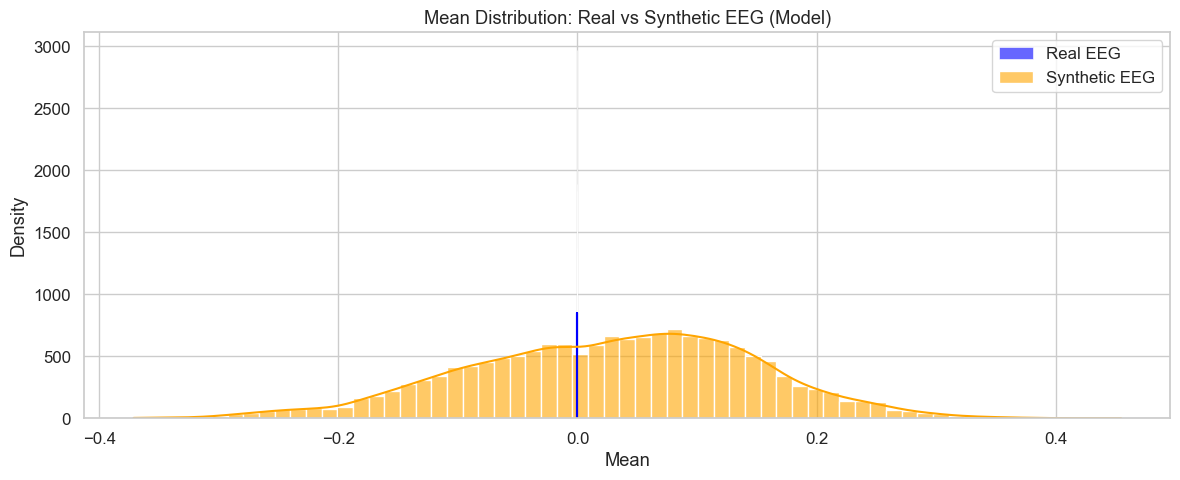

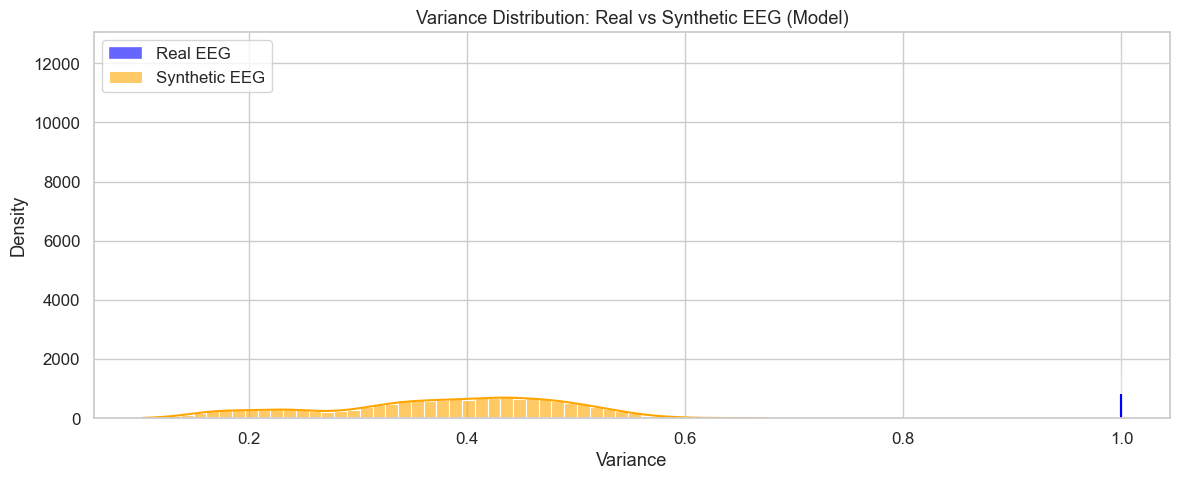

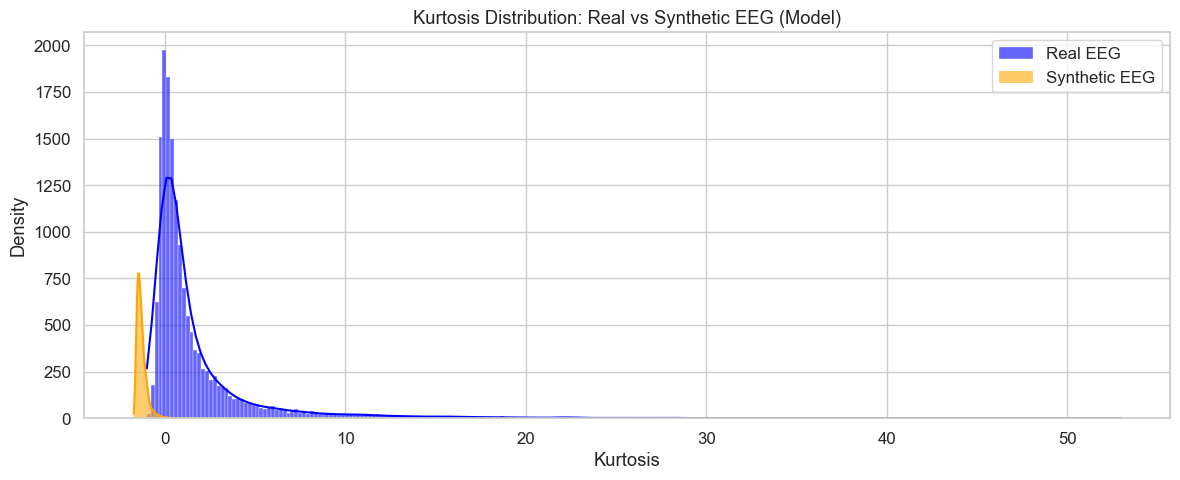

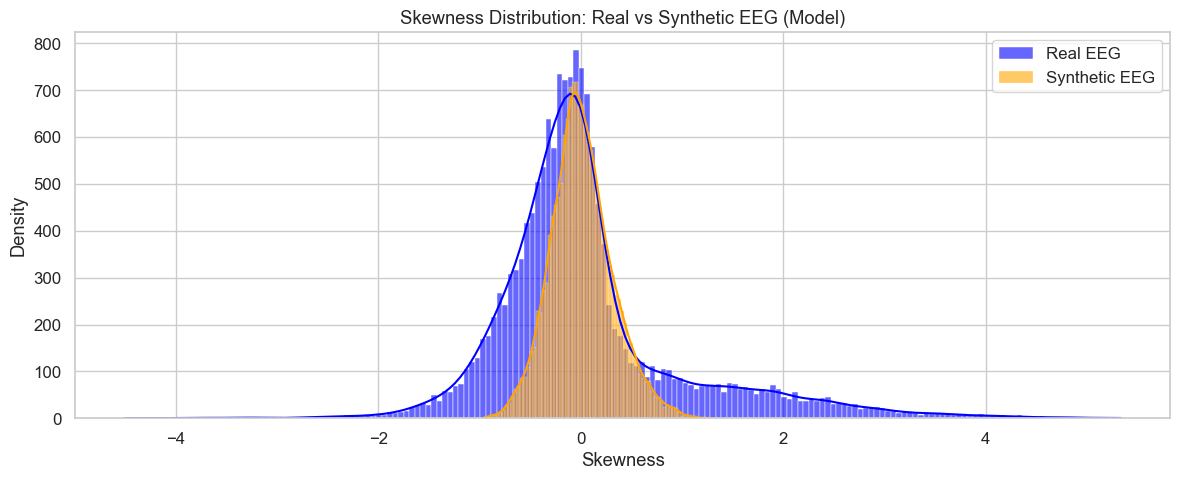

In [9]:
# Statistical comparison plots using library function
# (replaces inline plot_statistical_comparison)
fig1 = plot_statistical_comparison(real_mean, synthetic_mean, "Mean")
plt.show()

fig2 = plot_statistical_comparison(real_var, synthetic_var, "Variance")
plt.show()

fig3 = plot_statistical_comparison(real_kurt, synthetic_kurt, "Kurtosis")
plt.show()

fig4 = plot_statistical_comparison(real_skew, synthetic_skew, "Skewness")
plt.show()

#### Analysis of Statistical Feature Distributions (Mean, Variance, Kurtosis, Skewness)

**Interpretation**
- _Mean and variance:_ Ideally distributions of synthetic and real EEG should overlap closely. Significant deviations indicate the GAN isn’t accurately capturing the fundamental EEG statistics.
- _Kurtosis and Skewness:_ Kurtosis (peakedness) and skewness (asymmetry) should be similar, indicating realistic temporal EEG signal dynamics.

#### Analysis of Current plots
- Mean and variance
    - There are large discrepancies, REAL EEG has a very narrow mean distribution around zero, but Synthetic has broader variance, indicating synthetic EEG mean drift.
    - For variance Distribution, Real EEG variance distribution is sharply peaked at a single point (1.0), synthetic EEG has broader and smaller variance. We do think this is because of amplitude accuracy
- Kurtosis & Skewness:
    - These both have moderate to good overlap signifying good capture of waveform shapes

**In general**, this does signifies that our GAN model need more improvements in replicating mean and variance

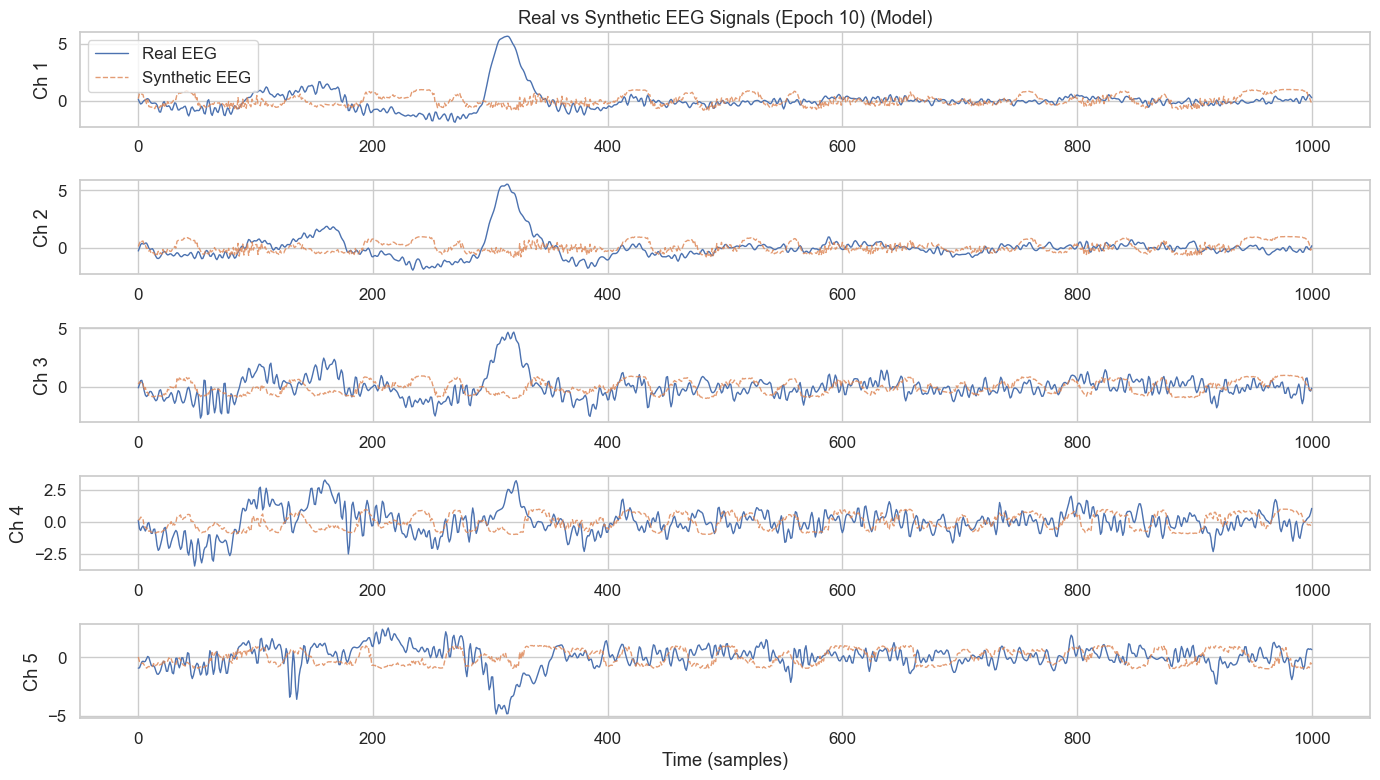

In [10]:
# Time-domain waveform visualization using library function
# (replaces inline plot_waveforms)
fig = plot_waveforms(real_data, synthetic_data, epoch_idx=10, channels=5)
plt.show()

#### Analysis of Time-Domain Waveform Comparison (Epoch Visualization)
**Interpretation**
- Realistic synthetic EEG signals must closely mimic real EEG signals visually in terms of waveform structure, amplitude fluctuations, and temporal dynamics.

#### Analysis of current:
- Overall good overlapping with occasional mismatch.

**This plot verifies our doubts about amplitude inconsistencies**

### Frequency-Domain Analysis

In [11]:
# Compute PSD using library function
# (replaces inline compute_psd)
real_psds, freqs = compute_psd(real_data, sfreq=200)
synthetic_psds, _ = compute_psd(synthetic_data.detach(), sfreq=200)

real_psds shape: (250, 63, 129)
synthetic_psds shape: (250, 63, 129)
freqs shape: (129,)


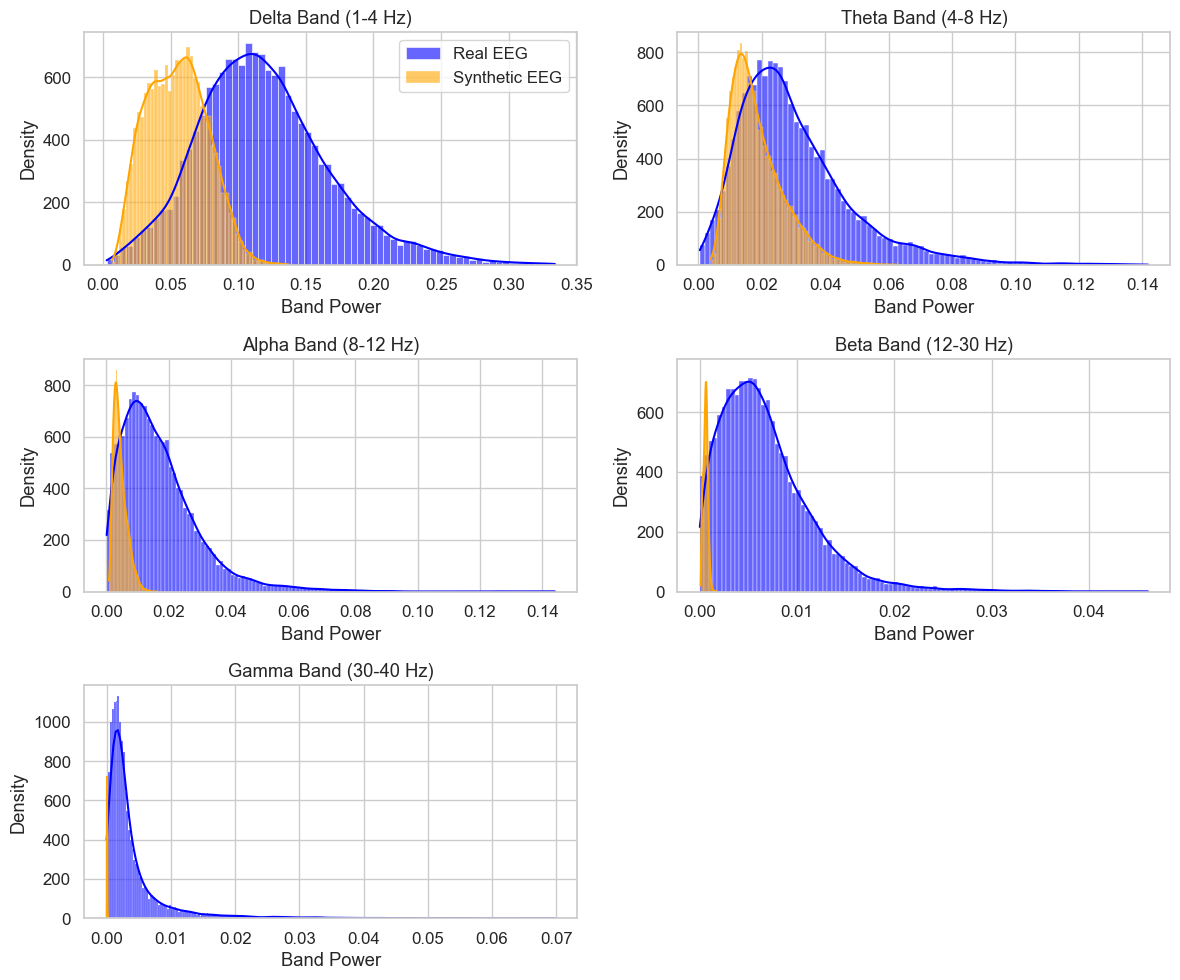

In [12]:
# Compute band powers using library function
# (replaces inline band_power and plot_band_power_comparison functions)
real_band_powers = compute_all_band_powers(real_psds, freqs)
synthetic_band_powers = compute_all_band_powers(synthetic_psds, freqs)

# Verify shapes
print(f"real_psds shape: {real_psds.shape}")
print(f"synthetic_psds shape: {synthetic_psds.shape}")
print(f"freqs shape: {freqs.shape}")

# Plot band power comparison using library function (requires bands parameter)
fig = plot_band_power_comparison(real_psds, synthetic_psds, freqs, EEG_BANDS)
plt.show()

#### Analysis of Band Power Distribution Analysis (Frequency Domain)

**Interpretation**
- EEG frequency bands (Delta, Theta, Alpha, Beta, Gamma) should exhibit similar distributions in synthetic EEG as in real EEG for realistic frequency-domain representation.

#### Analysis on current plots
- Delta Band: Partial overlap with some clear distributional shift, indicating underestimation of slow-wave EEG power by synthetic data.
- Theta, Alpha, Beta Bands: Limited overlap and narrower distribution in synthetic EEG—GAN struggles to accurately capture higher-frequency power distributions and overall frequency content realism.
- Gamma Band: Minimal overlap, highlighting significant limitations of synthetic EEG at high frequencies. GAN doesn’t effectively reproduce higher-frequency EEG dynamics.

**Okay these ones show clear issues with frequency domain realism. Frequency content at higher bands is insufficiently captured and needs significant improvement.**

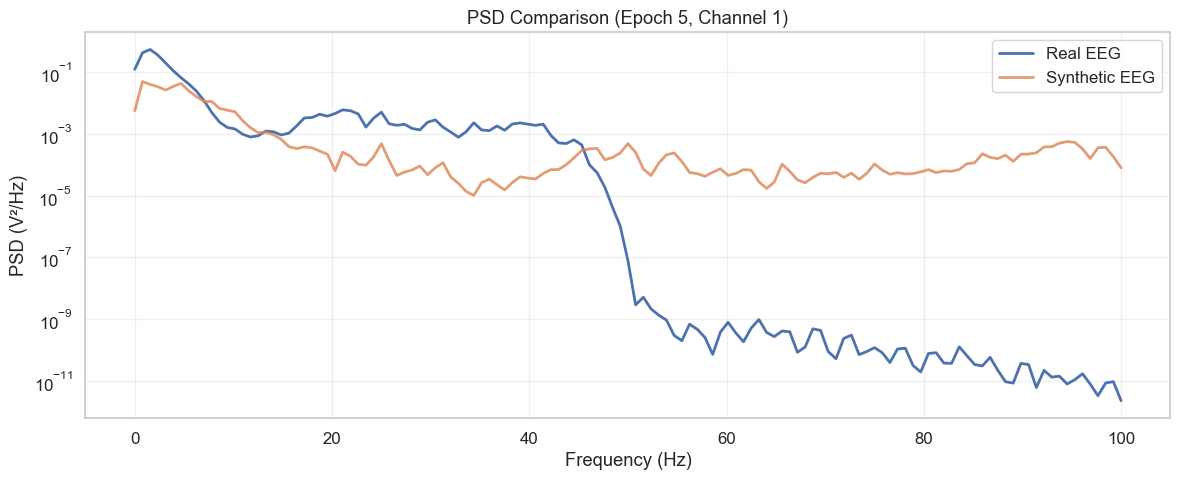

In [13]:
# PSD visualization using library function
# (replaces inline plot_psd_comparison)
fig = plot_psd_comparison(real_psds, synthetic_psds, freqs, epoch_idx=5, ch_idx=0)
plt.show()

#### Analysis of PSD comparison

**Interpretation**
- close overlapping, signifies synthetic EEG has a realistic frequency content and power distributions across all EEG frequencies.

#### Analysis on current plot
- Good for low frequencies (below ~20 Hz), but significant deviation at higher frequencies (>30 Hz)

### Heatmap and statistical Similarity

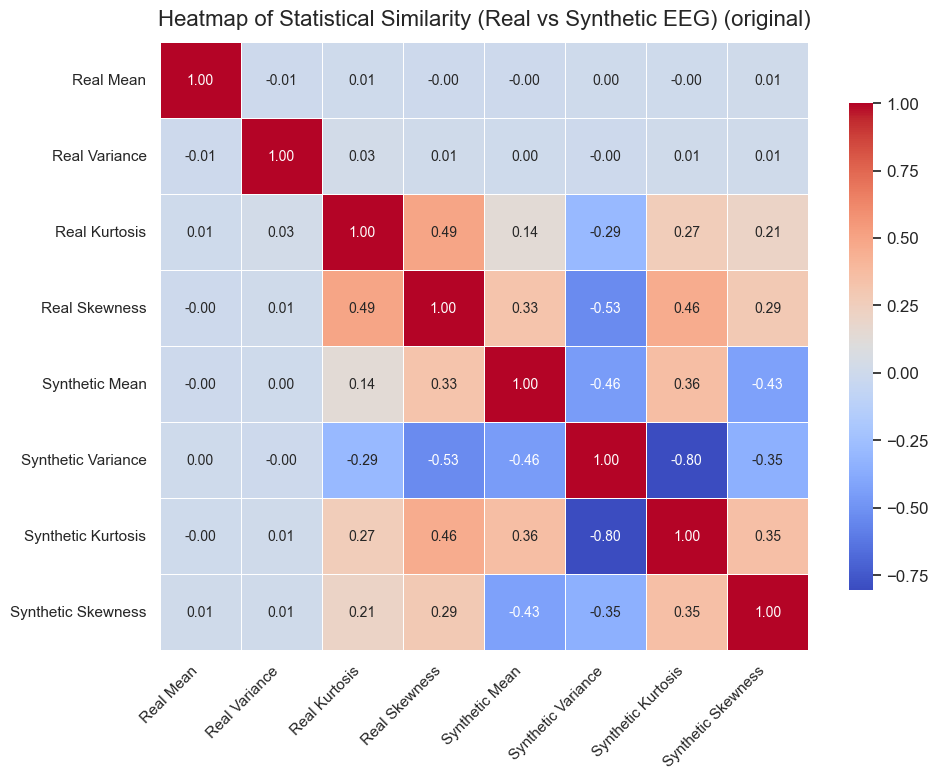

In [14]:
# Prepare features for heatmap
feature_labels = [
    'Real Mean', 'Real Variance', 'Real Kurtosis', 'Real Skewness',
    'Synthetic Mean', 'Synthetic Variance', 'Synthetic Kurtosis', 'Synthetic Skewness'
]

# Flatten features across epochs and channels for robust correlation
real_feats = np.vstack([
    real_mean.flatten(),
    real_var.flatten(),
    real_kurt.flatten(),
    real_skew.flatten()
])

synthetic_feats = np.vstack([
    synthetic_mean.flatten(),
    synthetic_var.flatten(),
    synthetic_kurt.flatten(),
    synthetic_skew.flatten()
])

# Plot similarity heatmap using library function
# (replaces inline plot_similarity_heatmap)
fig = plot_similarity_heatmap(real_feats, synthetic_feats, feature_labels, model_label="original")
plt.show()

#### Analysis of Heatmap of Statistical Similarity (Real vs. Synthetic EEG)

**Interpretability**
- correlations between statistical features (Mean, Variance, Kurtosis, and Skewness) for both real and synthetic EEG data.

#### Analysis for the current plot
- Mean and variance have low correlation
- Kurtosis and skewness are much more correlated for real and synthetic data

# Analysis of Improved Model

In [15]:
# Load enhanced generator using library function
# (replaces inline EEGGenerator class definition and checkpoint loading)
generator_enhanced = load_generator(
    model_variant="enhanced",
    device=device,
    latent_dim=latent_dim,
    n_channels=n_channels,
    target_signal_len=target_signal_len,
    num_classes=num_classes
)

print("Enhanced GAN model loaded successfully.")

Enhanced GAN model loaded successfully.


In [16]:
# synthetic data
noise = torch.randn(real_data.size(0), latent_dim).to(device)
synthetic_data_enh = generator_enhanced(noise, real_labels)

In [17]:
# verification of loading
print(f"Real EEG shape: {real_data.shape}")
print(f"Synthetic EEG shape: {synthetic_data_enh.shape}")

Real EEG shape: torch.Size([250, 63, 1001])
Synthetic EEG shape: torch.Size([250, 63, 1001])


## Time-Domain Analysis of improved model

In [18]:

real_mean, real_var, real_kurt, real_skew = compute_time_domain_features(real_data)
synthetic_mean_enh, synthetic_var_enh, synthetic_kurt_enh, synthetic_skew_enh = compute_time_domain_features(synthetic_data_enh.detach())

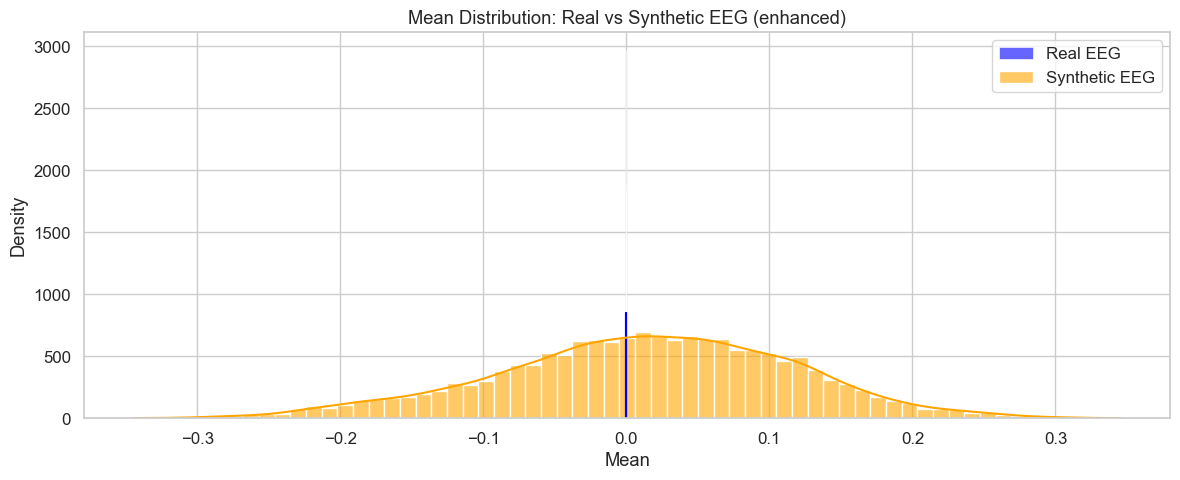

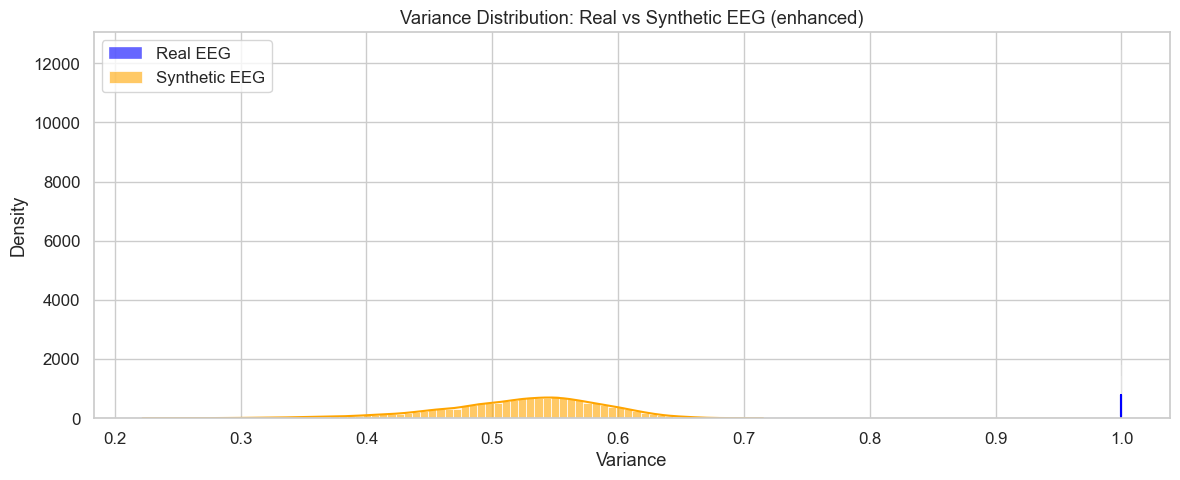

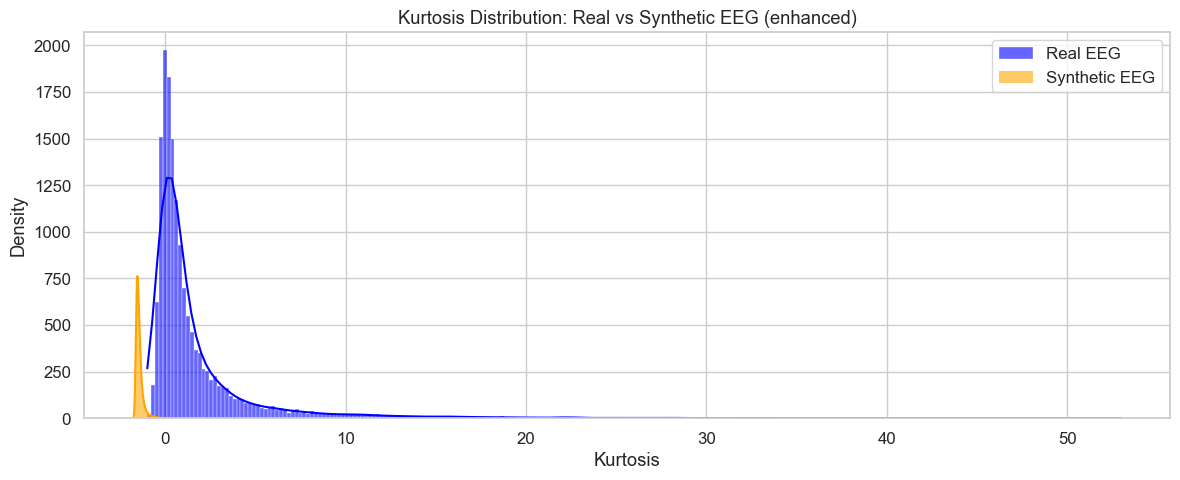

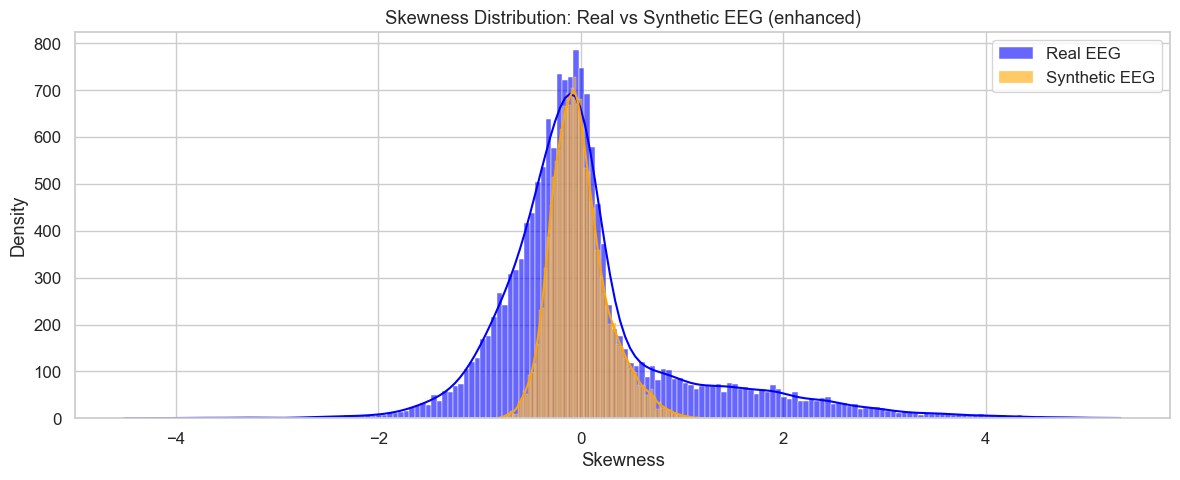

In [19]:
# Plotting Statistical Comparison using library function
fig1 = plot_statistical_comparison(real_mean, synthetic_mean_enh, "Mean", model_label="enhanced")
plt.show()

fig2 = plot_statistical_comparison(real_var, synthetic_var_enh, "Variance", model_label="enhanced")
plt.show()

fig3 = plot_statistical_comparison(real_kurt, synthetic_kurt_enh, "Kurtosis", model_label="enhanced")
plt.show()

fig4 = plot_statistical_comparison(real_skew, synthetic_skew_enh, "Skewness", model_label="enhanced")
plt.show()

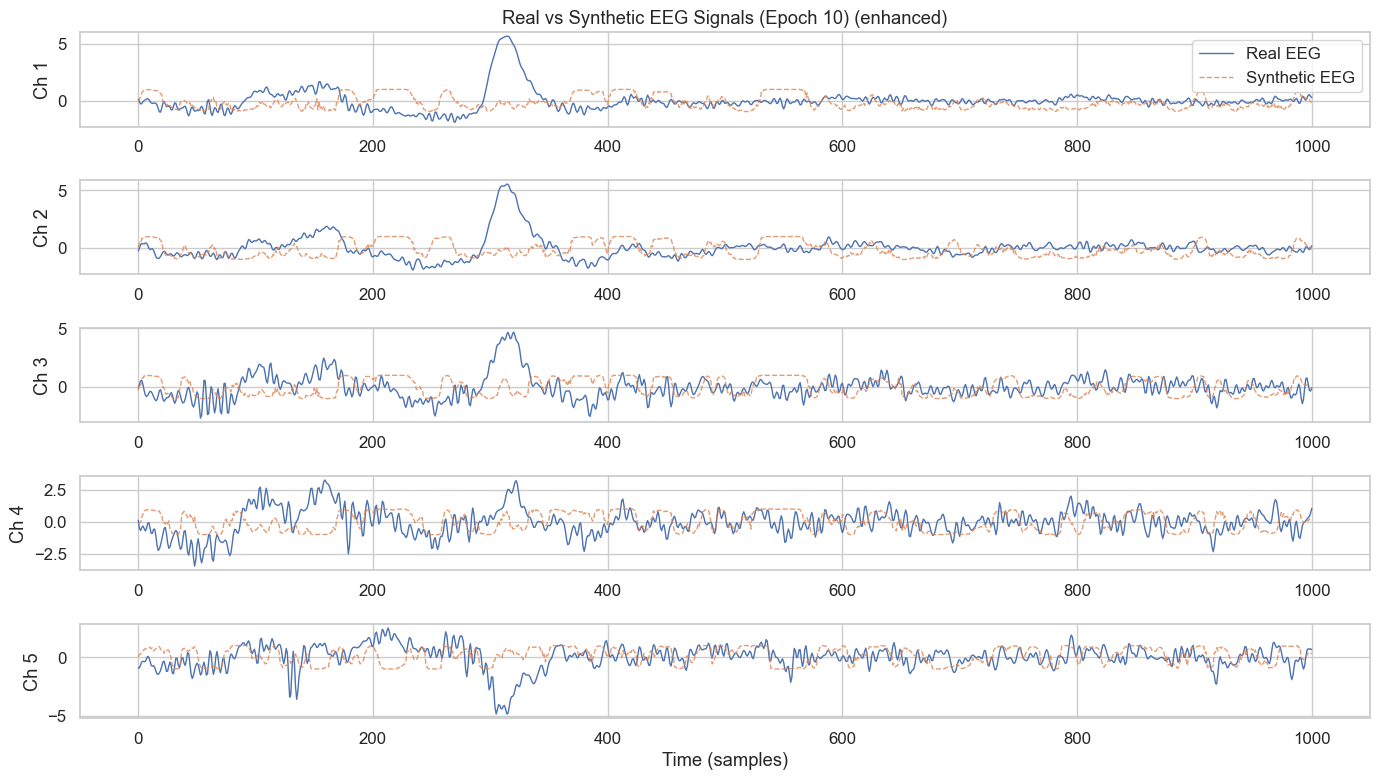

In [20]:
# Time-domain waveform visualization using library function
fig = plot_waveforms(real_data, synthetic_data_enh, epoch_idx=10, channels=5, model_label="enhanced")
plt.show()

### Frequency domain analysis

In [21]:
real_psds, freqs = compute_psd(real_data)
synthetic_psds_enh, _ = compute_psd(synthetic_data_enh.detach())

real_psds shape: (250, 63, 129)
synthetic_psds_enh shape: (250, 63, 129)
freqs shape: (129,)


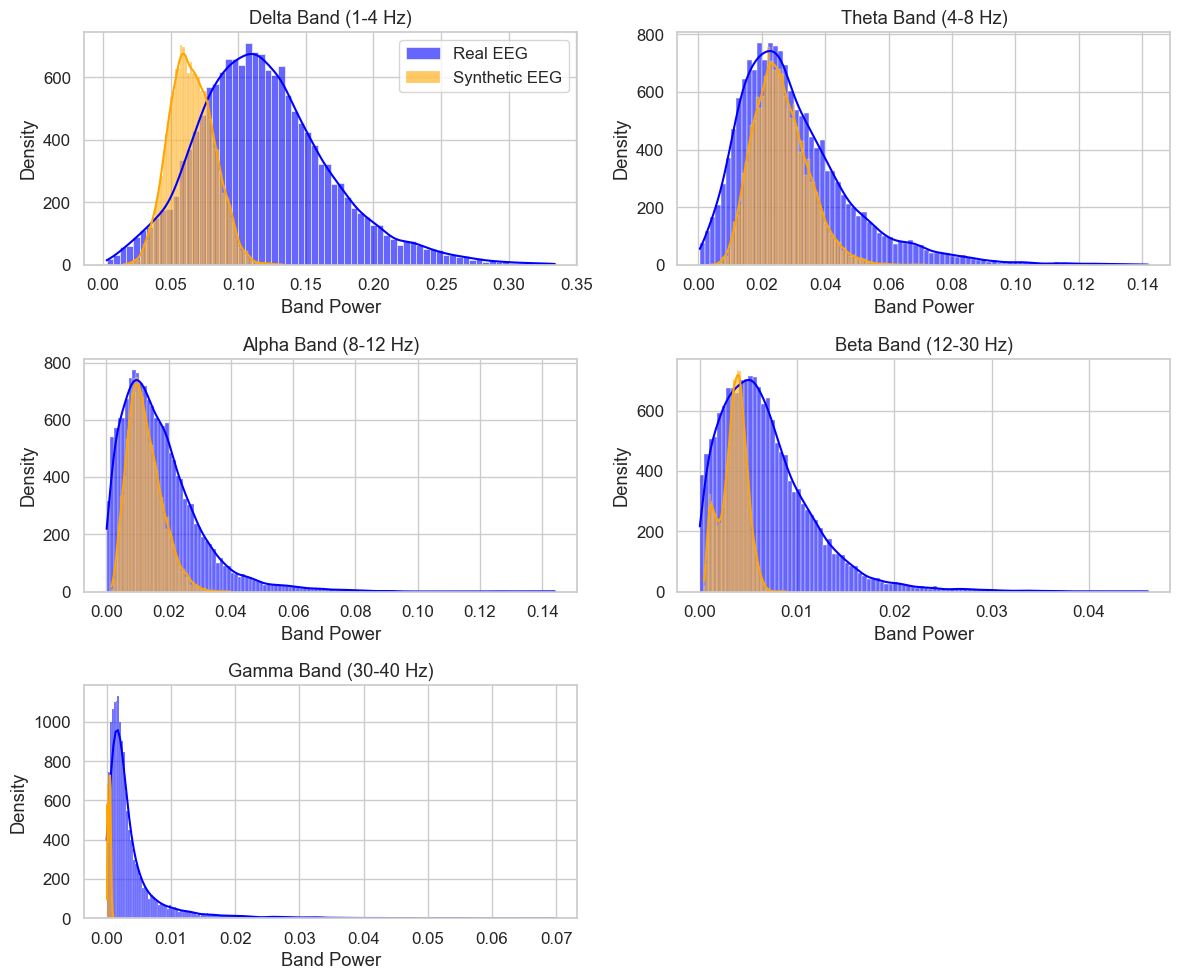

In [22]:
# Verify shapes explicitly
print(f"real_psds shape: {real_psds.shape}")
print(f"synthetic_psds_enh shape: {synthetic_psds_enh.shape}")
print(f"freqs shape: {freqs.shape}")

# Plot band power comparison using library function (requires bands parameter)
fig = plot_band_power_comparison(real_psds, synthetic_psds_enh, freqs, EEG_BANDS)
plt.show()

- We certainly see better overlapping and improvement from the data generated through improved model
> We couldn't see much difference in mean, variance, skewness and kurtosis, but the band power overlap visualisations certainly show us better overlappings of synthetic data

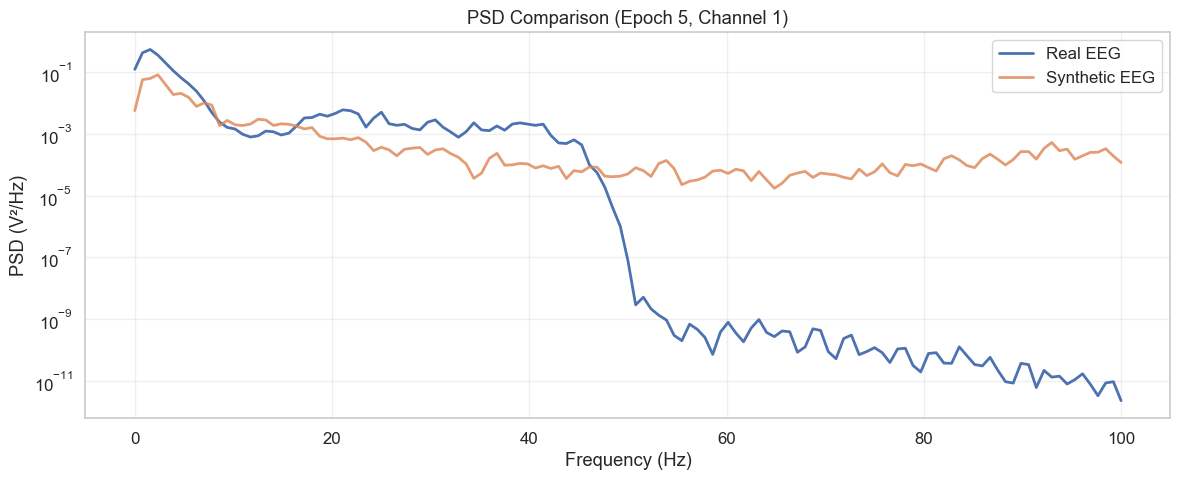

In [23]:
# PSD comparison using library function
fig = plot_psd_comparison(real_psds, synthetic_psds_enh, freqs, epoch_idx=5, ch_idx=0)
plt.show()

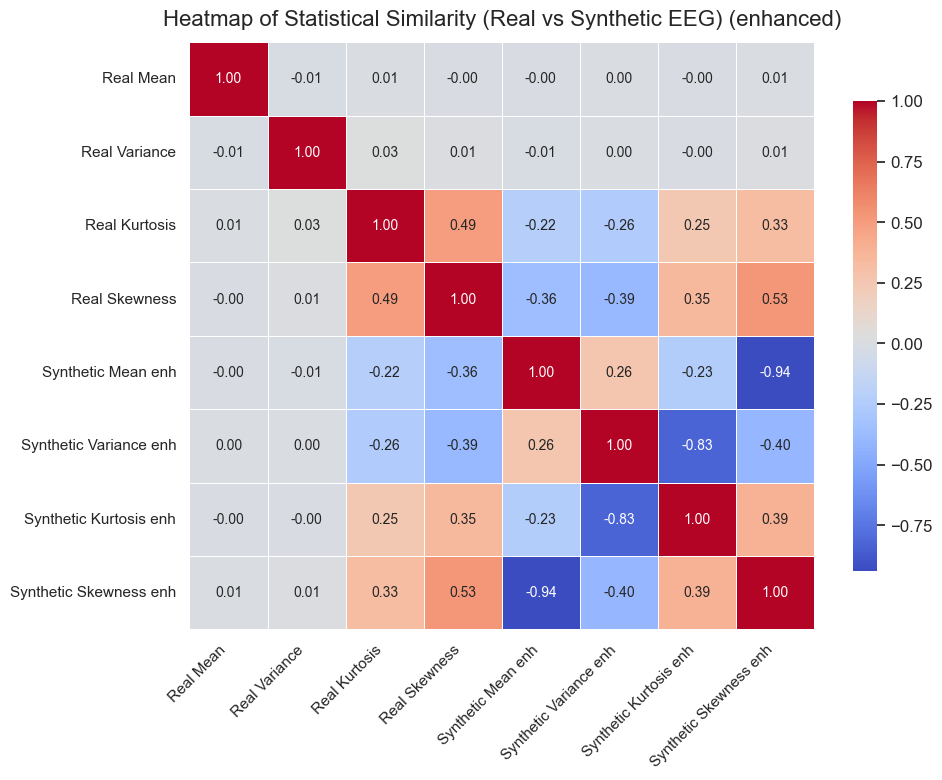

In [24]:
# Heatmap for statistical similarity using library function
feature_labels = [
    'Real Mean', 'Real Variance', 'Real Kurtosis', 'Real Skewness',
    'Synthetic Mean enh', 'Synthetic Variance enh', 'Synthetic Kurtosis enh', 'Synthetic Skewness enh'
]

# Flatten features across epochs and channels for robust correlation
real_feats = np.vstack([
    real_mean.flatten(),
    real_var.flatten(),
    real_kurt.flatten(),
    real_skew.flatten()
])

synthetic_feats_enh = np.vstack([
    synthetic_mean_enh.flatten(),
    synthetic_var_enh.flatten(),
    synthetic_kurt_enh.flatten(),
    synthetic_skew_enh.flatten()
])

# Plot similarity heatmap
fig = plot_similarity_heatmap(real_feats, synthetic_feats_enh, feature_labels, model_label="enhanced")
plt.show()

shows improved statistical similarity to real EEG, notably in reduced negative correlations between synthetic and real variance, kurtosis, and skewness. Particularly, synthetic skewness now strongly aligns with real skewness (correlation improved from 0.32 to 0.53), **meaning better generation of realistic EEG dynamics by the enhanced GAN model.**